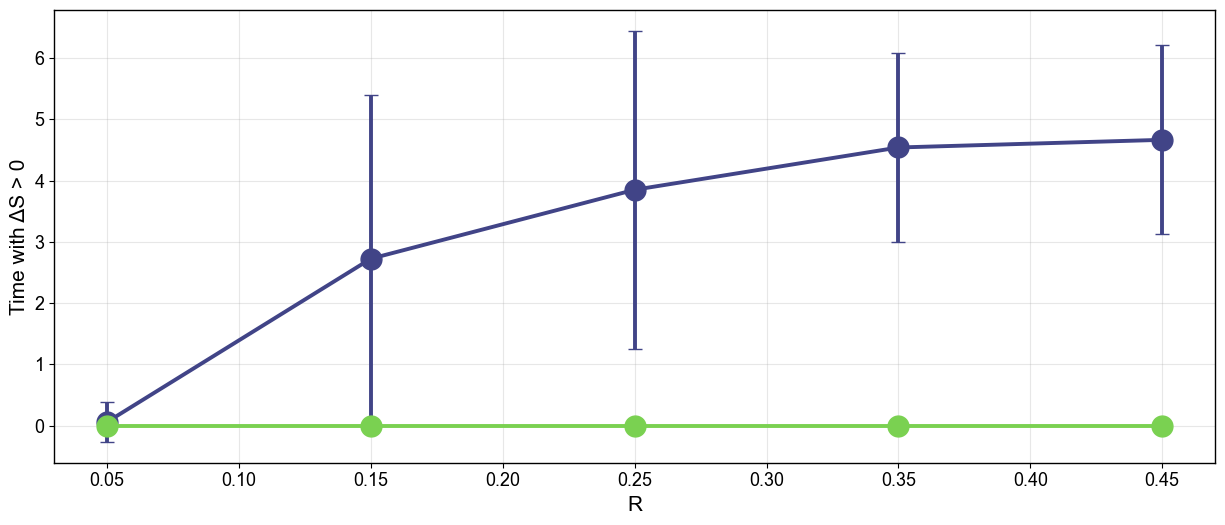

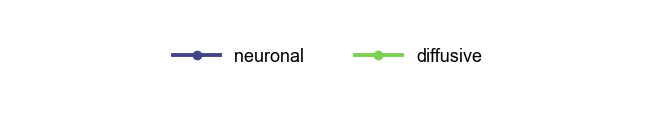

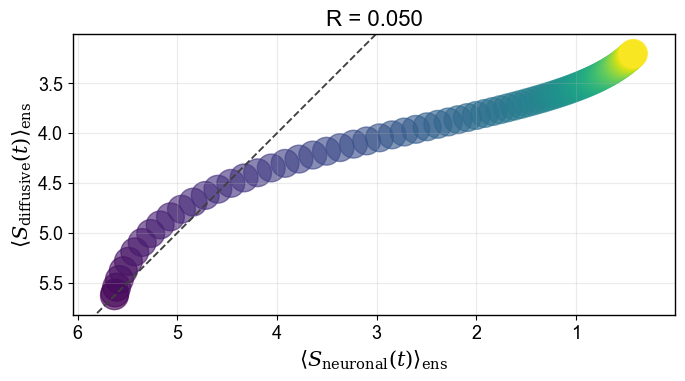

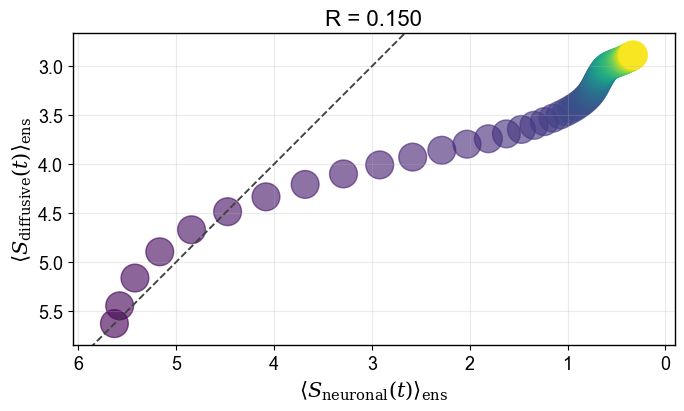

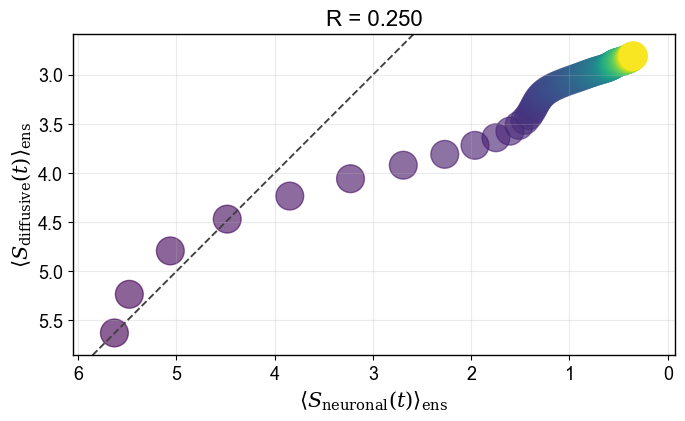

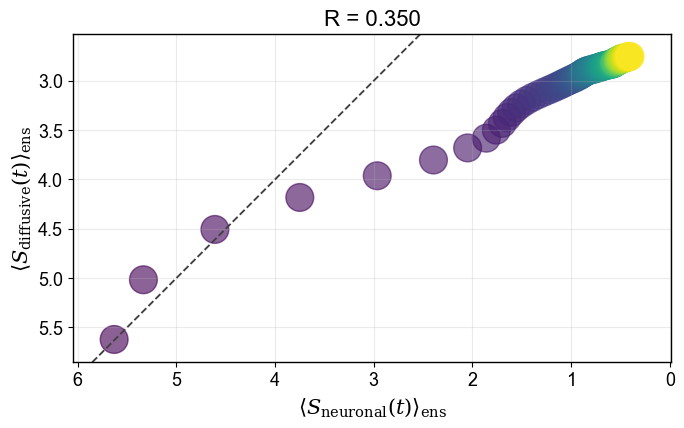

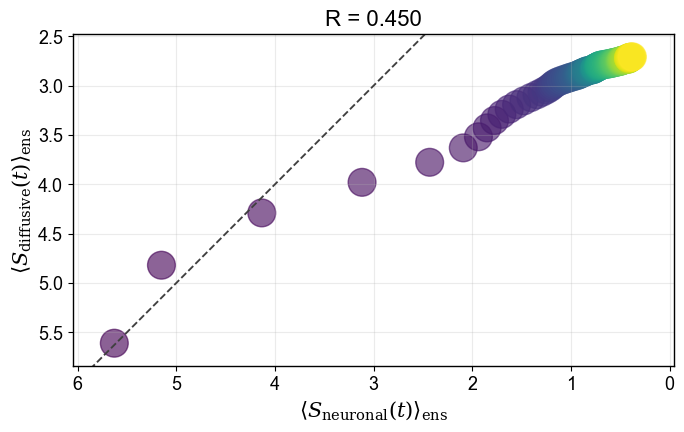

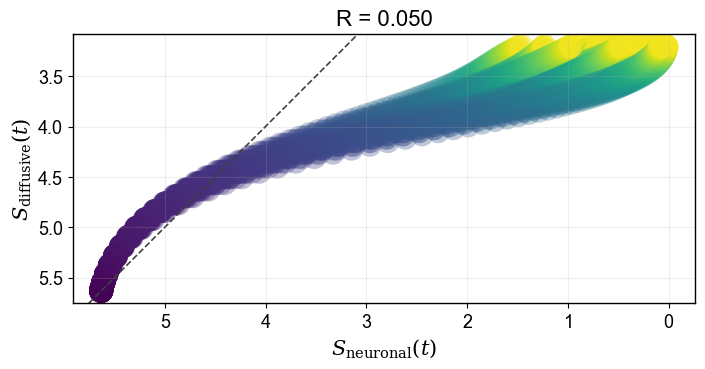

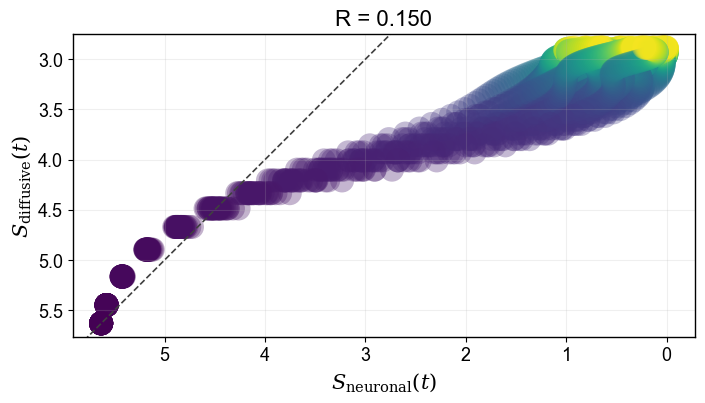

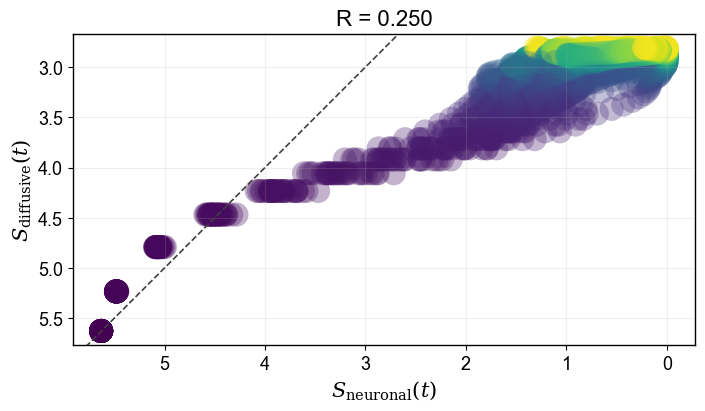

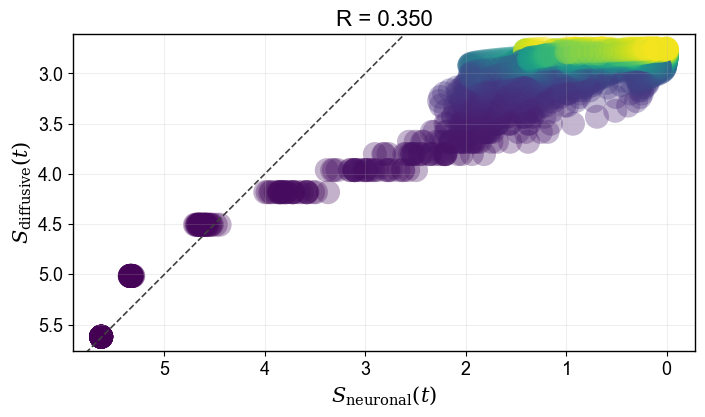

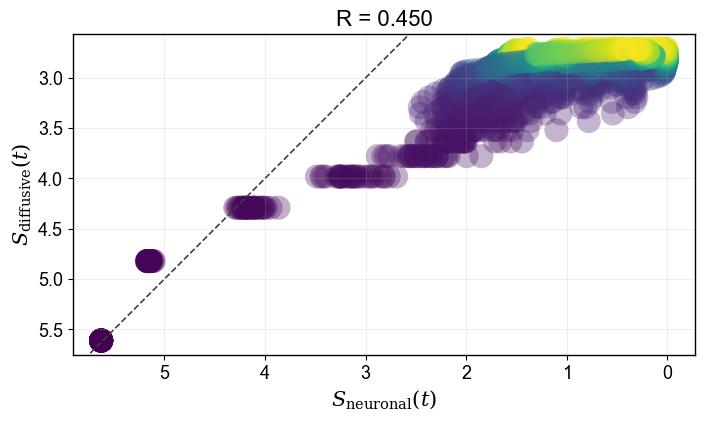

/tmp/ipykernel_20610/580984809.py:265: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figC.tight_layout()


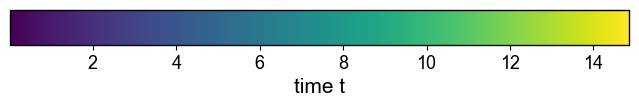

In [2]:
# ============================================================
# FULL NOTEBOOK-READY PLOTTING SCRIPT
# ============================================================

import os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ============================================================
# Global plotting style
# ============================================================
FONT_SIZE = 15

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": FONT_SIZE,

    "axes.titlesize": FONT_SIZE + 1,
    "axes.labelsize": FONT_SIZE,
    "axes.linewidth": 1.0,

    "xtick.labelsize": FONT_SIZE - 2,
    "ytick.labelsize": FONT_SIZE - 2,

    "legend.fontsize": FONT_SIZE - 2,
    "legend.frameon": False,

    # math (fix ⟨ ⟩)
    "mathtext.fontset": "dejavuserif",
    "mathtext.rm": "DejaVu Serif",
    "mathtext.it": "DejaVu Serif:italic",
    "mathtext.bf": "DejaVu Serif:bold",

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ============================================================
# Paths
# ============================================================
NPZ_FILE = "entropy_neuronal_vs_diffusive_ensemble1.npz"
OUTDIR = "figs_entropy"
os.makedirs(OUTDIR, exist_ok=True)

# ============================================================
# Load data
# ============================================================
data = np.load(NPZ_FILE, allow_pickle=True)

taus_samp = data["taus_samp"]
dt_eff    = float(data["dt_eff"])
R_grid    = data["R_grid"]

S_neur = data["S_neur"]   # (n_R, z, n_samp)
S_diff = data["S_diff"]   # (n_R, z, n_samp)

n_R, z, n_samp = S_neur.shape

# ============================================================
# Helpers
# ============================================================
def total_positive_time(S, dt_eff):
    S = np.asarray(S)
    mask = np.isfinite(S[:-1]) & np.isfinite(S[1:])
    return float(np.sum((S[1:] > S[:-1]) & mask) * dt_eff)

def zoom_limits(x, y, pad_frac=0.08, min_pad=1e-9):
    x = np.asarray(x); y = np.asarray(y)
    x_min, x_max = x.min(), x.max()
    y_min, y_max = y.min(), y.max()
    xr = x_max - x_min
    yr = y_max - y_min
    pad_x = max(pad_frac * (xr + 1e-12), min_pad)
    pad_y = max(pad_frac * (yr + 1e-12), min_pad)
    return (x_min - pad_x, x_max + pad_x,
            y_min - pad_y, y_max + pad_y)

def flatten_realization_time(Sr, taus_samp):
    return Sr.reshape(-1), np.tile(taus_samp, Sr.shape[0])

# ============================================================
# FIGURE 1: time with ΔS>0 vs R (mean ± std) — BIG, NO legend
# ============================================================
posT_neur_mean = np.full(n_R, np.nan)
posT_neur_std  = np.full(n_R, np.nan)
posT_diff_mean = np.full(n_R, np.nan)
posT_diff_std  = np.full(n_R, np.nan)

for r in range(n_R):
    Tn, Td = [], []
    for i in range(z):
        if np.all(np.isfinite(S_neur[r, i])):
            Tn.append(total_positive_time(S_neur[r, i], dt_eff))
        if np.all(np.isfinite(S_diff[r, i])):
            Td.append(total_positive_time(S_diff[r, i], dt_eff))
    if Tn:
        posT_neur_mean[r] = np.mean(Tn)
        posT_neur_std[r]  = np.std(Tn, ddof=1) if len(Tn) > 1 else 0.0
    if Td:
        posT_diff_mean[r] = np.mean(Td)
        posT_diff_std[r]  = np.std(Td, ddof=1) if len(Td) > 1 else 0.0

cmap = plt.get_cmap("viridis")
c_neur = cmap(0.20)
c_diff = cmap(0.80)

fig1, ax1 = plt.subplots(figsize=(12.5, 5.5))

ax1.errorbar(R_grid, posT_neur_mean, yerr=posT_neur_std,
             fmt="-o", lw=2.8, markersize=15, capsize=5, color=c_neur)
ax1.errorbar(R_grid, posT_diff_mean, yerr=posT_diff_std,
             fmt="-o", lw=2.8, markersize=15, capsize=5, color=c_diff)

ax1.set_xlabel("R")
ax1.set_ylabel("Time with ΔS > 0")
ax1.grid(True, alpha=0.3)

fig1.tight_layout()
fig1.savefig(os.path.join(
    OUTDIR, "time_positive_entropy_vs_R_with_std.pdf"),
    bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE 1b: STANDALONE LEGEND (separate PDF)
# ============================================================
figL, axL = plt.subplots(figsize=(6.8, 1.4))
axL.axis("off")

axL.plot([], [], "-o", lw=2.8, color=c_neur, label="neuronal ")
axL.plot([], [], "-o", lw=2.8, color=c_diff, label="diffusive")

axL.legend(
    loc="center",
    ncol=2,
    handlelength=2.6,
    columnspacing=2.5,
    frameon=False
)

figL.tight_layout()
figL.savefig(os.path.join(
    OUTDIR, "legend_time_positive_entropy.pdf"),
    bbox_inches="tight")
plt.show()

# ============================================================
# Shared colormap for time
# ============================================================
norm_t = Normalize(vmin=float(taus_samp[0]), vmax=float(taus_samp[-1]))
cmap_scatter = plt.get_cmap("viridis")

# ============================================================
# FIGURE 2: scatter of ensemble MEANS (unchanged transparency)
# ============================================================
POINT_SIZE = 400
POINT_ALPHA = 0.62

for r_idx, R in enumerate(R_grid):

    Sn_mean = np.nanmean(S_neur[r_idx], axis=0)
    Sd_mean = np.nanmean(S_diff[r_idx], axis=0)

    mask = np.isfinite(Sn_mean) & np.isfinite(Sd_mean)
    x, y = Sn_mean[mask], Sd_mean[mask]
    c = taus_samp[mask]

    if len(x) < 2:
        continue

    xmin, xmax, ymin, ymax = zoom_limits(x, y)
    dmin, dmax = min(xmin, ymin), max(xmax, ymax)

    fig2, ax2 = plt.subplots(figsize=(7.1, 6.4))
    ax2.scatter(x, y, c=c, s=POINT_SIZE,
                alpha=POINT_ALPHA,
                cmap=cmap_scatter, norm=norm_t)

    ax2.plot([dmin, dmax], [dmin, dmax], "--",
             lw=1.35, color="0.25")

    ax2.set_xlabel(r"$\langle S_{\mathrm{neuronal}}(t)\rangle_{\mathrm{ens}}$")
    ax2.set_ylabel(r"$\langle S_{\mathrm{diffusive}}(t)\rangle_{\mathrm{ens}}$")
    ax2.set_title(f"R = {R:.3f}")

    ax2.set_xlim(xmin, xmax)
    ax2.set_ylim(ymin, ymax)
    ax2.invert_xaxis()
    ax2.invert_yaxis()
    ax2.set_aspect("equal")

    ax2.grid(True, alpha=0.25)
    fig2.tight_layout()
    fig2.savefig(os.path.join(
        OUTDIR, f"scatter_mean_neur_vs_diff_R_{R:.3f}.pdf"),
        bbox_inches="tight")
    plt.show()

# ============================================================
# FIGURE 3: CLOUD scatter (all realizations × times)
# ============================================================
CLOUD_SIZE = 300
CLOUD_ALPHA = 0.32   # LESS transparent (as requested)

for r_idx, R in enumerate(R_grid):

    SrN = S_neur[r_idx]
    SrD = S_diff[r_idx]

    x_flat, t_flat = flatten_realization_time(SrN, taus_samp)
    y_flat, _      = flatten_realization_time(SrD, taus_samp)

    mask = np.isfinite(x_flat) & np.isfinite(y_flat)
    x, y, c = x_flat[mask], y_flat[mask], t_flat[mask]

    if len(x) < 10:
        continue

    xmin, xmax, ymin, ymax = zoom_limits(x, y, pad_frac=0.05)
    dmin, dmax = min(xmin, ymin), max(xmax, ymax)

    fig3, ax3 = plt.subplots(figsize=(7.3, 6.7))
    ax3.scatter(x, y, c=c, s=CLOUD_SIZE,
                alpha=CLOUD_ALPHA,
                cmap=cmap_scatter, norm=norm_t,
                linewidths=0)

    ax3.plot([dmin, dmax], [dmin, dmax], "--",
             lw=1.2, color="0.25")

    ax3.set_xlabel(r"$S_{\mathrm{neuronal}}(t)$")
    ax3.set_ylabel(r"$S_{\mathrm{diffusive}}(t)$")
    ax3.set_title(f"R = {R:.3f}")

    ax3.set_xlim(xmin, xmax)
    ax3.set_ylim(ymin, ymax)
    ax3.invert_xaxis()
    ax3.invert_yaxis()
    ax3.set_aspect("equal")

    ax3.grid(True, alpha=0.20)
    fig3.tight_layout()
    fig3.savefig(os.path.join(
        OUTDIR, f"scatter_cloud_neur_vs_diff_R_{R:.3f}.pdf"),
        bbox_inches="tight")
    plt.show()

# ============================================================
# FIGURE 4: standalone HORIZONTAL colorbar
# ============================================================
figC = plt.figure(figsize=(7.2, 1.25))
axC = figC.add_axes([0.08, 0.45, 0.86, 0.28])

sm = ScalarMappable(norm=norm_t, cmap=cmap_scatter)
sm.set_array([])

cb = plt.colorbar(sm, cax=axC, orientation="horizontal")
cb.set_label("time t")
cb.ax.tick_params(labelsize=FONT_SIZE - 2)

figC.tight_layout()
figC.savefig(os.path.join(
    OUTDIR, "colorbar_time_horizontal.pdf"),
    bbox_inches="tight")
plt.show()
